<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bar Charts**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be provided to you in the form of an RDBMS.

You will use SQL queries to extract the necessary data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data

-   Visualize the relationship between two features

-   Visualize the composition of data

-   Visualize comparison of data


## Setup: Working with the Database
**Install the needed libraries**


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [2]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [3]:
# Step 1: Download the dataset
# (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error
import pandas as pd
import matplotlib.pyplot as plt

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

# Step 2: Import necessary libraries and load the dataset
# (pandas and matplotlib already imported above)

# Display the first few rows to understand the structure of the data
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Visualizing Data Distributions


##### 1. Histogram of `ConvertedCompYearly`


Visualize the distribution of yearly compensation (`ConvertedCompYearly`) using a histogram.



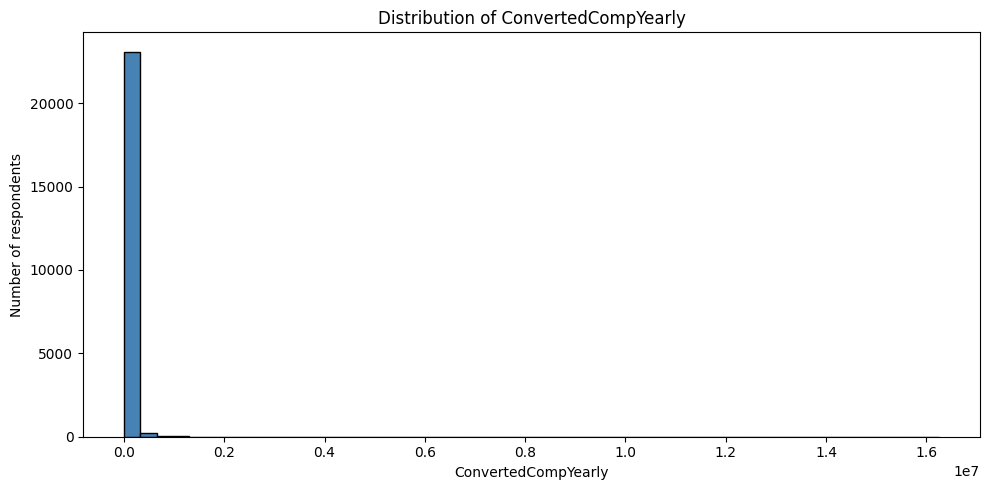

In [4]:
## Write your code here
# Histogram of ConvertedCompYearly
plt.figure(figsize=(10, 5))
df['ConvertedCompYearly'].dropna().plot(kind='hist', bins=50, color='steelblue', edgecolor='black')
plt.title('Distribution of ConvertedCompYearly')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

##### 2. Box Plot of `Age`


Since `Age` is categorical in the dataset, convert it to numerical values for a box plot.



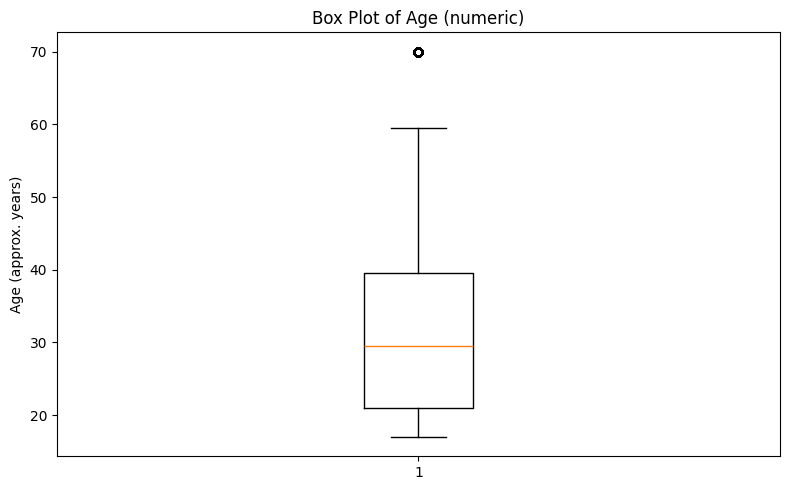

In [5]:
## Write your code here
# Box plot of Age (converted to numeric values)
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
df['AgeNum'] = df['Age'].map(age_mid)
plt.figure(figsize=(8, 5))
plt.boxplot(df['AgeNum'].dropna(), vert=True)
plt.title('Box Plot of Age (numeric)')
plt.ylabel('Age (approx. years)')
plt.tight_layout()
plt.show()

### Task 2: Visualizing Relationships in Data


##### 1. Scatter Plot of `Age_numeric` and `ConvertedCompYearly`


Explore the relationship between age and compensation.



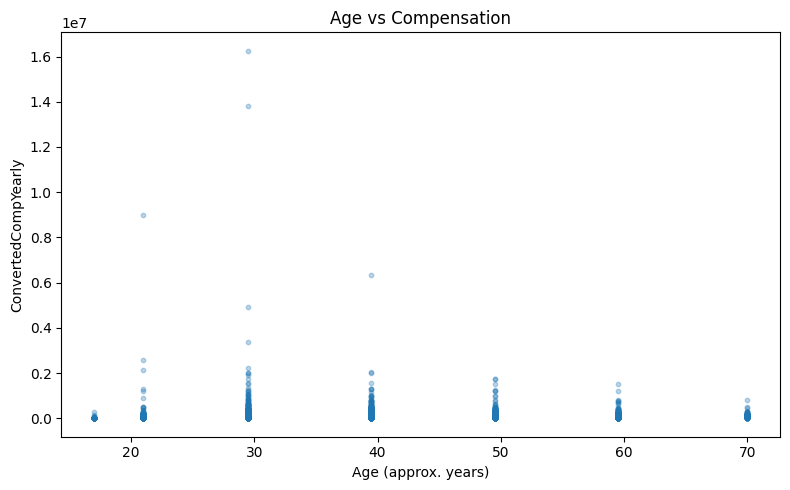

In [6]:
## Write your code here
# Scatter plot of Age (numeric) vs ConvertedCompYearly
plot_df = df[['Age', 'ConvertedCompYearly']].copy()
plot_df['AgeNum'] = plot_df['Age'].map({
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
})
plot_df = plot_df.dropna(subset=['AgeNum', 'ConvertedCompYearly'])
plt.figure(figsize=(8, 5))
plt.scatter(plot_df['AgeNum'], plot_df['ConvertedCompYearly'], alpha=0.3, s=10)
plt.title('Age vs Compensation')
plt.xlabel('Age (approx. years)')
plt.ylabel('ConvertedCompYearly')
plt.tight_layout()
plt.show()

##### 2. Bubble Plot of `ConvertedCompYearly` and `JobSatPoints_6` with `Age_numeric` as Bubble Size


Explore how compensation and job satisfaction are related, with age as the bubble size.


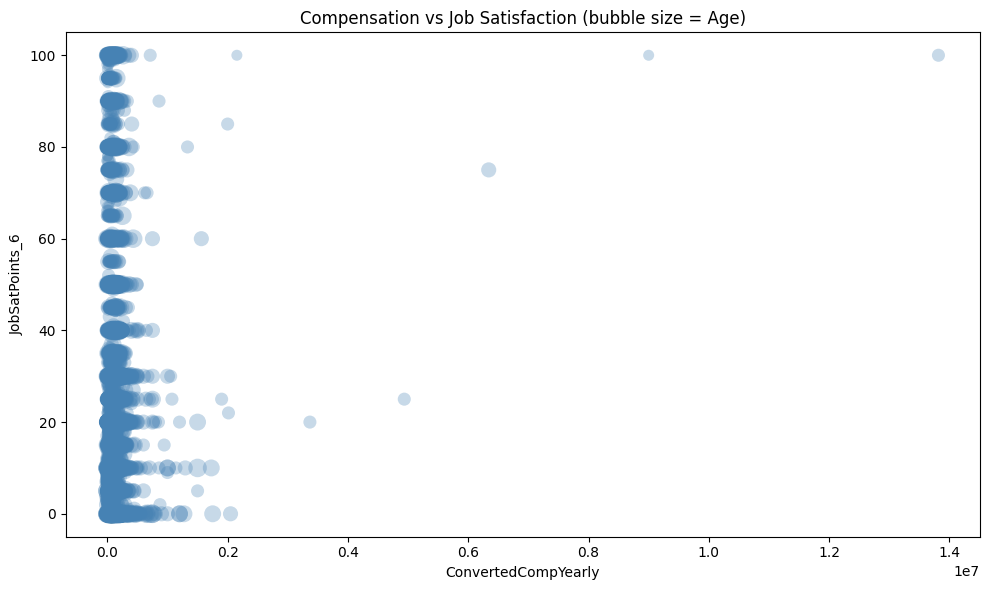

In [7]:
## Write your code here
# Bubble plot: ConvertedCompYearly (x) vs JobSatPoints_6 (y), bubble size = Age
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
bubble_df = df[['ConvertedCompYearly', 'JobSatPoints_6', 'Age']].dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6']).copy()
bubble_df['AgeNum'] = bubble_df['Age'].map(age_mid)
bubble_df = bubble_df.dropna(subset=['AgeNum'])
plt.figure(figsize=(10, 6))
plt.scatter(bubble_df['ConvertedCompYearly'], bubble_df['JobSatPoints_6'],
            s=bubble_df['AgeNum'] * 3, alpha=0.3, c='steelblue', edgecolors='none')
plt.title('Compensation vs Job Satisfaction (bubble size = Age)')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

### Task 3: Visualizing Composition of Data with Bar Charts


##### 1. Horizontal Bar Chart of `MainBranch` Distribution


Visualize the distribution of respondents’ primary roles to understand their professional focus.



MainBranch
I am a developer by profession                                                           50207
I am not primarily a developer, but I write code sometimes as part of my work/studies     6511
I am learning to code                                                                     3875
I code primarily as a hobby                                                               3334
I used to be a developer by profession, but no longer am                                  1510
Name: count, dtype: int64


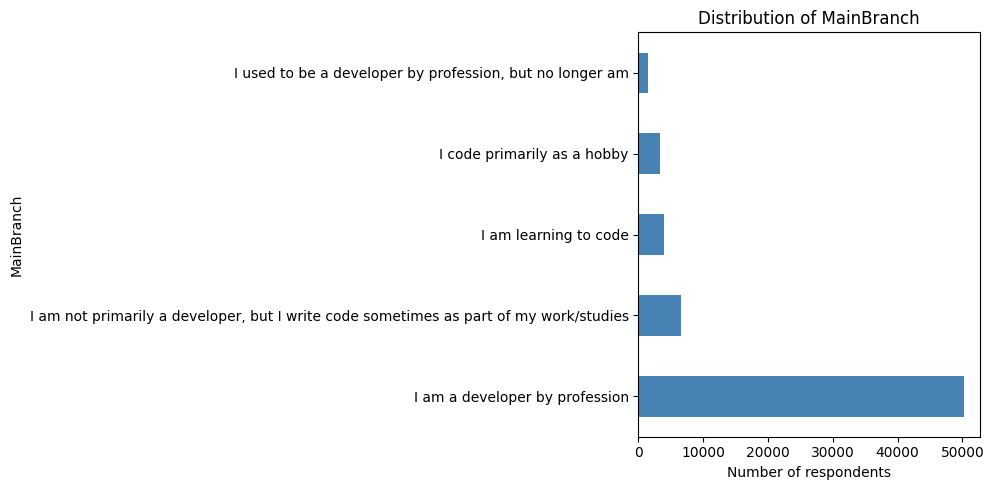

In [8]:
## Write your code here
# Horizontal bar chart of MainBranch distribution
branch_counts = df['MainBranch'].value_counts()
print(branch_counts)
plt.figure(figsize=(10, 5))
branch_counts.plot(kind='barh', color='steelblue')
plt.title('Distribution of MainBranch')
plt.xlabel('Number of respondents')
plt.ylabel('MainBranch')
plt.tight_layout()
plt.show()

##### 2. Vertical Bar Chart of Top 5 Programming Languages Respondents Want to Work With


Identify the most desired programming languages based on `LanguageWantToWorkWith`.



LanguageWantToWorkWith
Python        25047
JavaScript    23774
SQL           22400
HTML/CSS      20721
TypeScript    20239
Name: count, dtype: int64


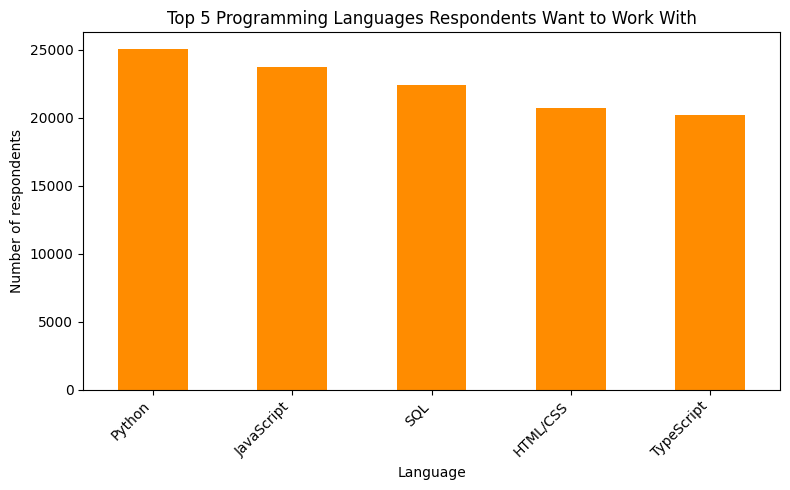

In [9]:
## Write your code here
# Vertical bar chart of top 5 programming languages respondents want to work with
lang_counts = df['LanguageWantToWorkWith'].dropna().str.split(';').explode().value_counts().head(5)
print(lang_counts)
plt.figure(figsize=(8, 5))
lang_counts.plot(kind='bar', color='darkorange')
plt.title('Top 5 Programming Languages Respondents Want to Work With')
plt.xlabel('Language')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 3. Stacked Bar Chart of Median `JobSatPoints_6` and `JobSatPoints_7` by Age Group


Compare job satisfaction metrics across different age groups with a stacked bar chart.


                    JobSatPoints_6  JobSatPoints_7
Age                                               
18-24 years old               15.0            20.0
25-34 years old               20.0            15.0
35-44 years old               20.0            15.0
45-54 years old               20.0            15.0
55-64 years old               20.0            20.0
65 years or older             20.0            15.0
Prefer not to say             10.0             7.0
Under 18 years old             1.5             5.0


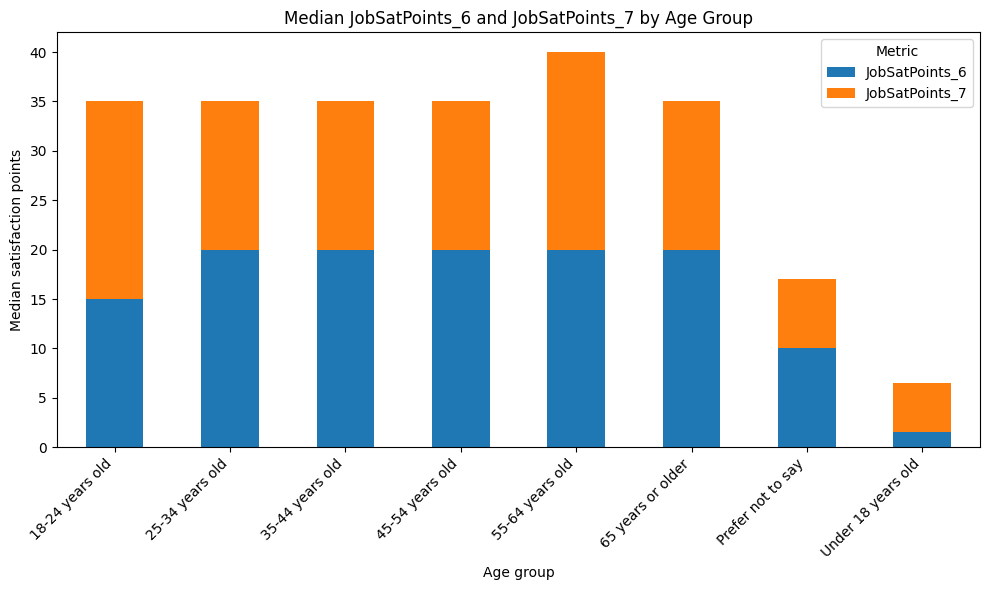

In [10]:
## Write your code here
# Stacked bar chart of median JobSatPoints_6 and JobSatPoints_7 by Age group
medians = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Median JobSatPoints_6 and JobSatPoints_7 by Age Group')
plt.xlabel('Age group')
plt.ylabel('Median satisfaction points')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

##### 4. Bar Chart of Database Popularity (`DatabaseHaveWorkedWith`)


Identify the most commonly used databases among respondents by visualizing `DatabaseHaveWorkedWith`.



DatabaseHaveWorkedWith
PostgreSQL              25536
MySQL                   21099
SQLite                  17365
Microsoft SQL Server    13275
MongoDB                 13007
Redis                   10463
MariaDB                  8991
Elasticsearch            6533
Oracle                   5273
Dynamodb                 4138
Name: count, dtype: int64


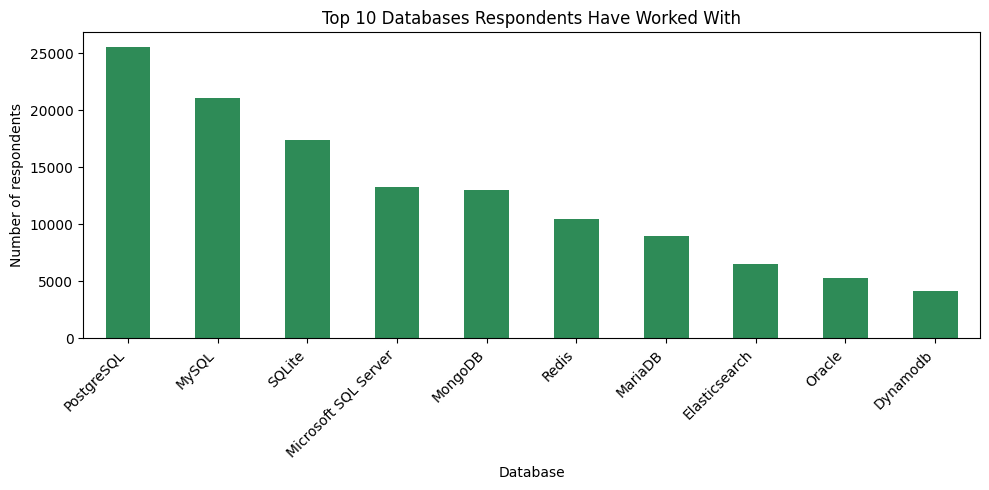

In [11]:
## Write your code here
# Bar chart of database popularity (DatabaseHaveWorkedWith)
db_counts = df['DatabaseHaveWorkedWith'].dropna().str.split(';').explode().value_counts().head(10)
print(db_counts)
plt.figure(figsize=(10, 5))
db_counts.plot(kind='bar', color='seagreen')
plt.title('Top 10 Databases Respondents Have Worked With')
plt.xlabel('Database')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Task 4: Visualizing Comparison of Data with Bar Charts


##### 1. Grouped Bar Chart of Median `ConvertedCompYearly` for Different Age Groups


Compare median compensation across multiple age groups with a grouped bar chart.



Age
18-24 years old        25000.0
25-34 years old        59825.0
35-44 years old        84796.0
45-54 years old        99099.0
55-64 years old       109691.0
65 years or older     106000.0
Prefer not to say     140000.0
Under 18 years old      7626.5
Name: ConvertedCompYearly, dtype: float64


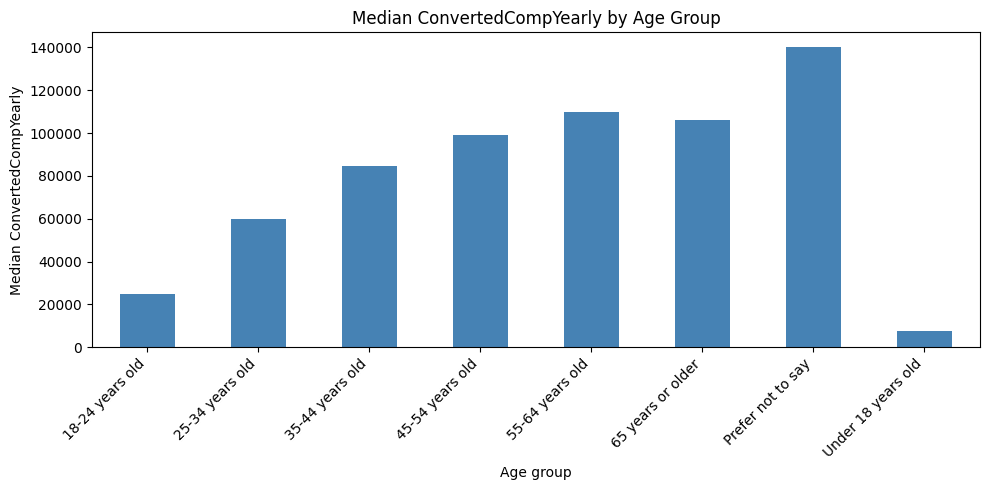

In [12]:
## Write your code here
# Grouped bar chart of median ConvertedCompYearly for different age groups
median_comp = df.groupby('Age')['ConvertedCompYearly'].median()
print(median_comp)
plt.figure(figsize=(10, 5))
median_comp.plot(kind='bar', color='steelblue')
plt.title('Median ConvertedCompYearly by Age Group')
plt.xlabel('Age group')
plt.ylabel('Median ConvertedCompYearly')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 2. Bar Chart of Respondent Count by Country


Show the distribution of respondents by country to see which regions are most represented.



Country
United States of America                                11095
Germany                                                  4947
India                                                    4231
United Kingdom of Great Britain and Northern Ireland     3224
Ukraine                                                  2672
France                                                   2110
Canada                                                   2104
Poland                                                   1534
Netherlands                                              1449
Brazil                                                   1375
Name: count, dtype: int64


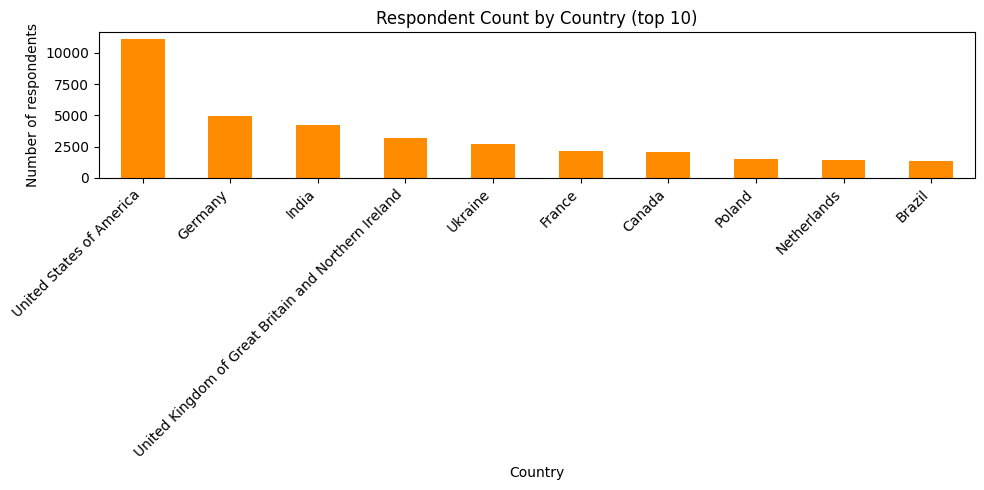

In [13]:
## Write your code here
# Bar chart of respondent count by country (top 10)
country_counts = df['Country'].value_counts().head(10)
print(country_counts)
plt.figure(figsize=(10, 5))
country_counts.plot(kind='bar', color='darkorange')
plt.title('Respondent Count by Country (top 10)')
plt.xlabel('Country')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Final Step: Review


This lab demonstrates how to create and interpret different types of bar charts, allowing you to analyze the composition, comparison, and distribution of categorical data in the Stack Overflow dataset, including main professional branches, programming language preferences, and compensation by age group. Bar charts effectively compare counts and median values across various categories.


## Summary


After completing this lab, you will be able to:
- Create a horizontal bar chart to visualize the distribution of respondents' primary roles, helping to understand their professional focus.
- Develop a vertical bar chart to identify the most desired programming languages based on the LanguageWantToWorkWith variable.
- Use a stacked bar chart to compare job satisfaction metrics across different age groups.
- Create a bar chart to visualize the most commonly used databases among respondents using the DatabaseHaveWorkedWith variable.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
